In [1]:
import csv
import hashlib
import io
from collections import Counter
from pathlib import Path, PurePosixPath

import keras
import numpy as np
import tensorflow as tf


PAPER9_SEED = 2026
PAPER9_IMAGE_SHAPE = (224, 224, 3)
PAPER9_DONOR_WIDTHS = {"vgg16": 4096, "resnet50": 2048, "inception_v3": 2048}
PAPER9_D1_CLASS_NAMES = (
    "Bacterial Leaf Blight",
    "Brown Spot",
    "Healthy Rice Leaf",
    "Leaf Blast",
    "Leaf Scald",
    "Narrow Brown Leaf Spot",
    "Rice Hispa",
    "Sheath Blight",
)
PAPER9_D1_MANIFEST_SHA256 = "3b756d0a4f0326a5e5123284aa884f23fe604d4ace6c56477491acd80ae728d0"


def paper9_mounted_dataset(slug):
    for root in (Path("/kaggle/input/datasets/nayebul0"), Path("/kaggle/input")):
        candidate = root / slug
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError(f"Attach the Kaggle input nayebul0/{slug}")


def verify_paper9_d1_inputs():
    image_root = paper9_mounted_dataset("assignment02-d1-original-rice-leaf-1701") / "Original Images"
    manifest = paper9_mounted_dataset("assignment02-verified-train-val-test-splits") / "D1_split_manifest.csv"
    raw = manifest.read_bytes()
    digest = hashlib.sha256(raw).hexdigest()
    if digest != PAPER9_D1_MANIFEST_SHA256:
        raise ValueError(f"Unexpected D1 manifest SHA-256: {digest}")
    rows = list(csv.DictReader(io.StringIO(raw.decode("utf-8-sig"))))
    counts = Counter(row["split"] for row in rows)
    if counts != {"train": 1156, "val": 247, "test": 248}:
        raise ValueError(f"Unexpected D1 split counts: {counts}")

    seen_paths = set()
    classes_by_split = {split: set() for split in counts}
    for row in rows:
        relative = PurePosixPath(row["rel_path"])
        class_id = int(row["class_id"])
        if row["dataset"] != "D1" or not 0 <= class_id < len(PAPER9_D1_CLASS_NAMES):
            raise ValueError(f"Invalid D1 dataset or class ID: {row}")
        if row["class_name"] != PAPER9_D1_CLASS_NAMES[class_id]:
            raise ValueError(f"Unexpected D1 class name: {row}")
        if not relative.parts or relative.is_absolute() or ".." in relative.parts or relative in seen_paths:
            raise ValueError(f"Invalid or repeated manifest path: {relative}")
        seen_paths.add(relative)
        classes_by_split[row["split"]].add(class_id)
        with image_root.joinpath(*relative.parts).open("rb") as image_file:
            actual = hashlib.file_digest(image_file, "sha256").hexdigest()
        if actual != row["file_sha256"]:
            raise ValueError(f"D1 image SHA-256 mismatch: {relative}")

    expected_classes = set(range(len(PAPER9_D1_CLASS_NAMES)))
    if any(class_ids != expected_classes for class_ids in classes_by_split.values()):
        raise ValueError(f"Unexpected classes by split: {classes_by_split}")
    print(f"D1 manifest SHA-256: {digest}")
    print(f"D1 train/val/test: {counts['train']}/{counts['val']}/{counts['test']}")
    print(f"D1 classes: {dict(enumerate(PAPER9_D1_CLASS_NAMES))}")
    print(f"D1 image files verified against manifest: {len(rows):,}")
    return image_root, manifest, rows


def build_paper9_donor(name, weights):
    if name == "vgg16":
        base = keras.applications.VGG16(weights=weights, input_shape=PAPER9_IMAGE_SHAPE)
        donor = keras.Model(base.input, base.get_layer("fc2").output, name="paper9_vgg16_fc2")
    else:
        application = {"resnet50": keras.applications.ResNet50, "inception_v3": keras.applications.InceptionV3}[name]
        donor = application(
            include_top=False,
            weights=weights,
            input_shape=PAPER9_IMAGE_SHAPE,
            pooling="avg",
        )
    donor.trainable = False
    return donor


def build_paper9_classifier(component_count, class_count):
    if component_count < 4:
        raise ValueError("The valid convolution and pooling require at least four PCA components.")
    branch_input = keras.Input(shape=(component_count, 1), name="branch_input")
    features = keras.layers.Conv1D(32, 3, padding="valid", activation="relu", name="component_conv")(branch_input)
    features = keras.layers.MaxPooling1D(2, strides=2, name="component_pool")(features)
    features = keras.layers.Flatten(name="component_flatten")(features)
    features = keras.layers.Dense(256, activation="relu", name="branch_dense")(features)
    features = keras.layers.Dropout(0.3, seed=PAPER9_SEED, name="branch_dropout")(features)
    shared_branch = keras.Model(branch_input, features, name="shared_twin_branch")

    pca_input = keras.Input(shape=(component_count,), name="pca_components")
    sequence = keras.layers.Reshape((component_count, 1), name="pca_sequence")(pca_input)
    first = shared_branch(sequence)
    second = shared_branch(sequence)
    merged = keras.layers.Add(name="twin_add")([first, second])
    logits = keras.layers.Dense(class_count, name="class_logits")(merged)
    probabilities = keras.layers.Softmax(name="class_probabilities")(logits)
    return keras.Model(pca_input, probabilities, name="paper9_twin_cnn")


def check_paper9_d1_architecture():
    keras.utils.set_random_seed(PAPER9_SEED)
    gpu_devices = tf.config.list_physical_devices("GPU")
    device = "/GPU:0" if gpu_devices else "/CPU:0"
    print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__} | Device: {device}")

    descriptors = []
    sample_images = tf.random.uniform((2, *PAPER9_IMAGE_SHAPE), dtype=tf.float32)
    for name, width in PAPER9_DONOR_WIDTHS.items():
        keras.backend.clear_session()
        with tf.device(device):
            donor = build_paper9_donor(name, weights=None)
            values = donor(sample_images, training=False)
            tf.debugging.assert_equal(tf.shape(values), [2, width])
            tf.debugging.assert_all_finite(values, name)
            if donor.trainable_weights:
                raise AssertionError(f"{name} has trainable extractor weights")
            descriptors.append(values.numpy())
            print(f"{name}: {tuple(values.shape)}")
        del donor

    fused = np.concatenate(descriptors, axis=1)
    np.testing.assert_equal(fused.shape, (2, 8192))
    print(f"Fused descriptor: {fused.shape}")

    component_count = 32
    class_count = len(PAPER9_D1_CLASS_NAMES)
    keras.backend.clear_session()
    with tf.device(device):
        model = build_paper9_classifier(component_count, class_count)
        merge_layer = model.get_layer("twin_add")
        probe = keras.Model(model.input, [*merge_layer.input, merge_layer.output, model.output])
        synthetic_pca = tf.random.normal((2, component_count))
        first, second, merged, probabilities = probe(synthetic_pca, training=False)
        tf.debugging.assert_equal(tf.shape(first), [2, 256])
        tf.debugging.assert_equal(tf.shape(probabilities), [2, class_count])
        tf.debugging.assert_near(first, second, atol=1e-6)
        tf.debugging.assert_near(merged, 2.0 * first, atol=1e-6)
        tf.debugging.assert_near(tf.reduce_sum(probabilities, axis=1), tf.ones(2), atol=1e-6)
        tf.debugging.assert_near(model(synthetic_pca[:1], training=False), probabilities[:1], atol=1e-5)

        shared_branch = model.get_layer("shared_twin_branch")
        if len(model.trainable_weights) != len(shared_branch.trainable_weights) + 2:
            raise AssertionError("Unexpected trainable weights outside the shared branch and output layer.")
        labels = tf.one_hot([0, 1], class_count)
        loss_fn = keras.losses.CategoricalCrossentropy()
        with tf.GradientTape() as tape:
            loss = loss_fn(labels, model(synthetic_pca, training=True))
        tf.debugging.assert_all_finite(loss, "Synthetic training loss")
        gradients = tape.gradient(loss, model.trainable_weights)
        for weight, gradient in zip(model.trainable_weights, gradients, strict=True):
            if gradient is None:
                raise AssertionError(f"Missing gradient: {weight.name}")
            tf.debugging.assert_all_finite(gradient, weight.name)
            tf.debugging.assert_positive(tf.linalg.global_norm([gradient]), message=weight.name)

    print(f"Synthetic PCA input: (2, {component_count}) | D1 probabilities: {tuple(probabilities.shape)}")
    print(f"Tied branch outputs and elementwise addition verified | synthetic loss: {float(loss):.6f}")
    print("PAPER 9 D1 INPUTS AND ARCHITECTURE PASSED")


paper9_d1_image_root, paper9_d1_manifest_path, paper9_d1_rows = verify_paper9_d1_inputs()
check_paper9_d1_architecture()


D1 manifest SHA-256: 3b756d0a4f0326a5e5123284aa884f23fe604d4ace6c56477491acd80ae728d0
D1 train/val/test: 1156/247/248
D1 classes: {0: 'Bacterial Leaf Blight', 1: 'Brown Spot', 2: 'Healthy Rice Leaf', 3: 'Leaf Blast', 4: 'Leaf Scald', 5: 'Narrow Brown Leaf Spot', 6: 'Rice Hispa', 7: 'Sheath Blight'}
D1 image files verified against manifest: 1,651
TensorFlow: 2.21.0 | Keras: 3.13.2 | Device: /GPU:0
vgg16: (2, 4096)
resnet50: (2, 2048)
inception_v3: (2, 2048)
Fused descriptor: (2, 8192)
Synthetic PCA input: (2, 32) | D1 probabilities: (2, 8)
Tied branch outputs and elementwise addition verified | synthetic loss: 2.348121
PAPER 9 D1 INPUTS AND ARCHITECTURE PASSED


In [2]:
import hashlib
import json
from pathlib import Path

import keras
import tensorflow as tf


PAPER9_D1_IMAGENET_DIR = Path("/kaggle/working/paper9_twin_cnn_d1/imagenet")
PAPER9_IMAGENET_BASE_URL = "https://storage.googleapis.com/tensorflow/keras-applications"
PAPER9_IMAGENET_SOURCES = {
    "vgg16": (
        "vgg16/vgg16_weights_tf_dim_ordering_tf_kernels.h5",
        "64373286793e3c8b2b4e3219cbf3544b",
        "fc2",
    ),
    "resnet50": (
        "resnet/resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5",
        "4d473c1dd8becc155b73f8504c6f6626",
        "avg_pool",
    ),
    "inception_v3": (
        "inception_v3/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5",
        "bcbd6486424b2319ff4ef7d526e38f63",
        "global_average_pool",
    ),
}


def paper9_weight_digest(path, algorithm):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, algorithm).hexdigest()


def verify_paper9_imagenet_weights():
    PAPER9_D1_IMAGENET_DIR.mkdir(parents=True, exist_ok=True)
    device = "/GPU:0" if tf.config.list_physical_devices("GPU") else "/CPU:0"
    probe = tf.random.stateless_uniform((2, *PAPER9_IMAGE_SHAPE), seed=(PAPER9_SEED, 2))
    report = {
        "dataset": "D1",
        "manifest_sha256": PAPER9_D1_MANIFEST_SHA256,
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
        "device": device,
        "probe_input_shape": list(probe.shape),
        "probe_input_range": [0, 1],
        "donors": {},
    }

    for name, (source_path, expected_md5, feature_tap) in PAPER9_IMAGENET_SOURCES.items():
        url = f"{PAPER9_IMAGENET_BASE_URL}/{source_path}"
        filename = source_path.rsplit("/", 1)[-1]
        weight_path = Path(keras.utils.get_file(
            fname=filename,
            origin=url,
            file_hash=expected_md5,
            hash_algorithm="md5",
            cache_dir=str(PAPER9_D1_IMAGENET_DIR),
            cache_subdir="keras_weights",
        ))
        actual_md5 = paper9_weight_digest(weight_path, "md5")
        if actual_md5 != expected_md5:
            raise ValueError(f"Unexpected ImageNet weight checksum for {name}: {weight_path}")
        sha256 = paper9_weight_digest(weight_path, "sha256")

        keras.backend.clear_session()
        with tf.device(device):
            donor = build_paper9_donor(name, weights=str(weight_path))
            descriptor = donor(probe, training=False)
            tf.debugging.assert_equal(tf.shape(descriptor), [2, PAPER9_DONOR_WIDTHS[name]])
            tf.debugging.assert_all_finite(descriptor, f"{name} descriptor")
            tf.debugging.assert_positive(tf.linalg.norm(descriptor, axis=1), message=name)
            if donor.trainable_weights:
                raise AssertionError(f"{name} has trainable extractor weights")
            output_layer = donor.layers[-1]
            if name == "vgg16":
                if output_layer.name != feature_tap:
                    raise AssertionError(f"Unexpected feature tap for {name}: {output_layer.name}")
            elif not isinstance(output_layer, keras.layers.GlobalAveragePooling2D):
                raise AssertionError(f"Expected global average pooling for {name}: {output_layer.name}")
            report["donors"][name] = {
                "url": url,
                "file": str(weight_path),
                "bytes": weight_path.stat().st_size,
                "md5": actual_md5,
                "sha256": sha256,
                "feature_tap": feature_tap,
                "output_layer": output_layer.name,
                "descriptor_width": int(descriptor.shape[-1]),
                "extractor_parameters": donor.count_params(),
            }
            print(f"{name}: {tuple(descriptor.shape)} | {feature_tap} | frozen")
            print(f"{name} ImageNet SHA-256: {sha256}")
        del donor, descriptor

    keras.backend.clear_session()
    report_path = PAPER9_D1_IMAGENET_DIR / "Paper9_D1_ImageNet_Weights.json"
    temporary_report = report_path.with_suffix(".json.tmp")
    temporary_report.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    temporary_report.replace(report_path)
    print(f"ImageNet weight report: {report_path}")
    print("PAPER 9 D1 IMAGENET WEIGHTS PASSED")
    return report_path, report["donors"]


paper9_d1_imagenet_report, paper9_d1_imagenet_donors = verify_paper9_imagenet_weights()


553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
vgg16: (2, 4096) | fc2 | frozen
vgg16 ImageNet SHA-256: 8b81f25be4126c5ec088f19901b2b34e9a40e3d46246c9d208a3d727462b4f5c
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
resnet50: (2, 2048) | avg_pool | frozen
resnet50 ImageNet SHA-256: 66c8b43daff3fcc15bc4f30e3d2a167e21a14d9c9598a5394e5516471f4af504
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
inception_v3: (2, 2048) | global_average_pool | frozen
inception_v3 ImageNet SHA-256: 9617109a16463f250180008f9818336b767bdf5164315e8cd5761a8c34caa62a
ImageNet weight report: /kaggle/working/paper9_twin_cnn_d1/imagenet/Paper9_D1_ImageNet_Weights.json
PAPER 9 D1 IMAGENET WEIGHTS PASSED


In [3]:
import hashlib
import json
from collections import Counter
from pathlib import Path, PurePosixPath

import cv2
import numpy as np
import PIL
from PIL import Image as PillowImage
from PIL import ImageDraw, ImageOps


PAPER9_D1_PREPROCESS_DIR = Path("/kaggle/working/paper9_twin_cnn_d1/preprocessing")
PAPER9_TRAIN_VARIANTS = 2
PAPER9_ROTATION_DEGREES = (-20.0, 20.0)
PAPER9_ZOOM_RANGE = (0.9, 1.1)
PAPER9_BRIGHTNESS_RANGE = (0.8, 1.2)
PAPER9_FLIP_PROBABILITY = 0.5


def paper9_augmentation_parameters(relative_path, view_id):
    key = f"{PAPER9_SEED}:{relative_path}:{view_id}".encode("utf-8")
    seed = int.from_bytes(hashlib.sha256(key).digest()[:16], "big")
    rng = np.random.Generator(np.random.PCG64(seed))
    return {
        "horizontal_flip": bool(rng.random() < PAPER9_FLIP_PROBABILITY),
        "vertical_flip": bool(rng.random() < PAPER9_FLIP_PROBABILITY),
        "rotation_degrees": float(rng.uniform(*PAPER9_ROTATION_DEGREES)),
        "zoom": float(rng.uniform(*PAPER9_ZOOM_RANGE)),
        "brightness_multiplier": float(rng.uniform(*PAPER9_BRIGHTNESS_RANGE)),
    }


def paper9_load_rgb_view(image_root, row, view_id=0):
    if not 0 <= view_id <= PAPER9_TRAIN_VARIANTS:
        raise ValueError(f"Invalid view: {view_id}")
    if view_id and row["split"] != "train":
        raise ValueError("Augmented views require a training row.")

    relative_path = row["rel_path"]
    path = image_root.joinpath(*PurePosixPath(relative_path).parts)
    with PillowImage.open(path) as image:
        rgb = np.asarray(ImageOps.exif_transpose(image).convert("RGB"))

    height, width, _ = PAPER9_IMAGE_SHAPE
    pixels = cv2.resize(rgb, (width, height), interpolation=cv2.INTER_LINEAR)
    if view_id:
        params = paper9_augmentation_parameters(relative_path, view_id)
        if params["horizontal_flip"]:
            pixels = cv2.flip(pixels, 1)
        if params["vertical_flip"]:
            pixels = cv2.flip(pixels, 0)
        center = ((width - 1) / 2, (height - 1) / 2)
        affine = cv2.getRotationMatrix2D(center, params["rotation_degrees"], params["zoom"])
        pixels = cv2.warpAffine(
            pixels, affine, (width, height), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101
        )
        pixels = np.clip(pixels.astype(np.float32) * params["brightness_multiplier"], 0, 255)
    return pixels.astype(np.float32) / np.float32(255)


def paper9_feature_view_plan(rows):
    entries = []
    for split in ("train", "val"):
        selected = sorted((row for row in rows if row["split"] == split), key=lambda row: row["rel_path"])
        for row in selected:
            view_count = 1 + PAPER9_TRAIN_VARIANTS if split == "train" else 1
            entries.extend((row, view_id) for view_id in range(view_count))
    return entries


def check_paper9_d1_preprocessing():
    PAPER9_D1_PREPROCESS_DIR.mkdir(parents=True, exist_ok=True)
    entries = paper9_feature_view_plan(paper9_d1_rows)
    counts = Counter(row["split"] for row, _ in entries)
    expected = {"train": 3468, "val": 247}
    if counts != expected:
        raise AssertionError(f"Unexpected view counts: {counts}")
    if len({(row["rel_path"], view_id) for row, view_id in entries}) != len(entries):
        raise AssertionError("Repeated image/view identifier.")
    view_counts = Counter((row["split"], view_id) for row, view_id in entries)
    expected_views = {("train", 0): 1156, ("train", 1): 1156, ("train", 2): 1156, ("val", 0): 247}
    if view_counts != expected_views:
        raise AssertionError(f"Unexpected counts by view: {view_counts}")

    preview = PillowImage.new("RGB", (672, 28 + len(PAPER9_D1_CLASS_NAMES) * 252), "white")
    draw = ImageDraw.Draw(preview)
    for column, title in enumerate(("Original training view", "Augmented view 1", "Augmented view 2")):
        draw.text((column * 224 + 8, 8), title, fill="black")

    samples = []
    for class_id, class_name in enumerate(PAPER9_D1_CLASS_NAMES):
        for split in ("train", "val"):
            candidates = [row for row, view_id in entries if row["split"] == split
                          and int(row["class_id"]) == class_id and view_id == 0]
            rng = np.random.default_rng(PAPER9_SEED + 10 * class_id + int(split == "val"))
            row = candidates[int(rng.integers(len(candidates)))]
            view_ids = range(1 + PAPER9_TRAIN_VARIANTS) if split == "train" else (0,)
            sample = {"split": split, "class_name": class_name, "image": row["rel_path"], "views": []}
            seen_hashes = set()
            for view_id in view_ids:
                pixels = paper9_load_rgb_view(paper9_d1_image_root, row, view_id)
                repeated = paper9_load_rgb_view(paper9_d1_image_root, row, view_id)
                np.testing.assert_array_equal(pixels, repeated)
                if pixels.shape != PAPER9_IMAGE_SHAPE or pixels.dtype != np.float32:
                    raise AssertionError(f"Unexpected image shape or dtype: {row['rel_path']}")
                minimum, maximum = float(pixels.min()), float(pixels.max())
                if not np.isfinite(pixels).all() or not 0 <= minimum <= maximum <= 1:
                    raise AssertionError(f"Unexpected normalized pixel range: {row['rel_path']}")

                digest = hashlib.sha256(pixels.tobytes()).hexdigest()
                seen_hashes.add(digest)
                sample["views"].append({
                    "view_id": view_id,
                    "pixel_sha256": digest,
                    "pixel_min": minimum,
                    "pixel_max": maximum,
                    "augmentation": paper9_augmentation_parameters(row["rel_path"], view_id) if view_id else None,
                })
                if split == "train":
                    y = 28 + class_id * 252
                    tile = PillowImage.fromarray(np.rint(pixels * 255).astype(np.uint8))
                    preview.paste(tile, (view_id * 224, y + 24))
                    draw.text((view_id * 224 + 8, y + 4), class_name, fill="black")
            if len(seen_hashes) != len(view_ids):
                raise AssertionError(f"Sampled views have identical pixels: {row['rel_path']}")
            if split == "val":
                try:
                    paper9_load_rgb_view(paper9_d1_image_root, row, 1)
                except ValueError as error:
                    if str(error) != "Augmented views require a training row.":
                        raise
                else:
                    raise AssertionError("Validation augmentation was accepted.")
            samples.append(sample)

    preview_path = PAPER9_D1_PREPROCESS_DIR / "Paper9_D1_Augmentation_Preview.png"
    preview.save(preview_path)
    report_path = PAPER9_D1_PREPROCESS_DIR / "Paper9_D1_Preprocessing_Check.json"
    report = {
        "manifest_sha256": PAPER9_D1_MANIFEST_SHA256,
        "opencv": cv2.__version__,
        "pillow": PIL.__version__,
        "numpy": np.__version__,
        "image_shape": PAPER9_IMAGE_SHAPE,
        "normalization": "RGB divided by 255",
        "resize": "bilinear",
        "seed": PAPER9_SEED,
        "training_augmented_views_per_image": PAPER9_TRAIN_VARIANTS,
        "rotation_degrees": PAPER9_ROTATION_DEGREES,
        "zoom_range": PAPER9_ZOOM_RANGE,
        "brightness_multiplier_range": PAPER9_BRIGHTNESS_RANGE,
        "flip_probability_per_axis": PAPER9_FLIP_PROBABILITY,
        "affine_border": "reflect_101",
        "planned_counts": dict(counts),
        "samples": samples,
    }
    report_path.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    print(f"OpenCV: {cv2.__version__} | RGB float32 | 224 x 224 | range [0, 1]")
    print(f"Train: {view_counts['train', 0]:,} originals + {2 * view_counts['train', 0]:,} augmented = {counts['train']:,} planned views")
    print(f"Validation: {counts['val']:,} original views | no test preprocessing")
    print("32 sampled views checked across eight classes | repeatability passed")
    print(f"Preview: {preview_path}")
    print(f"Report: {report_path}")
    print("PAPER 9 D1 PREPROCESSING CHECK PASSED")
    return entries, report_path


paper9_d1_feature_entries, paper9_d1_preprocessing_report = check_paper9_d1_preprocessing()


OpenCV: 4.14.0 | RGB float32 | 224 x 224 | range [0, 1]
Train: 1,156 originals + 2,312 augmented = 3,468 planned views
Validation: 247 original views | no test preprocessing
32 sampled views checked across eight classes | repeatability passed
Preview: /kaggle/working/paper9_twin_cnn_d1/preprocessing/Paper9_D1_Augmentation_Preview.png
Report: /kaggle/working/paper9_twin_cnn_d1/preprocessing/Paper9_D1_Preprocessing_Check.json
PAPER 9 D1 PREPROCESSING CHECK PASSED


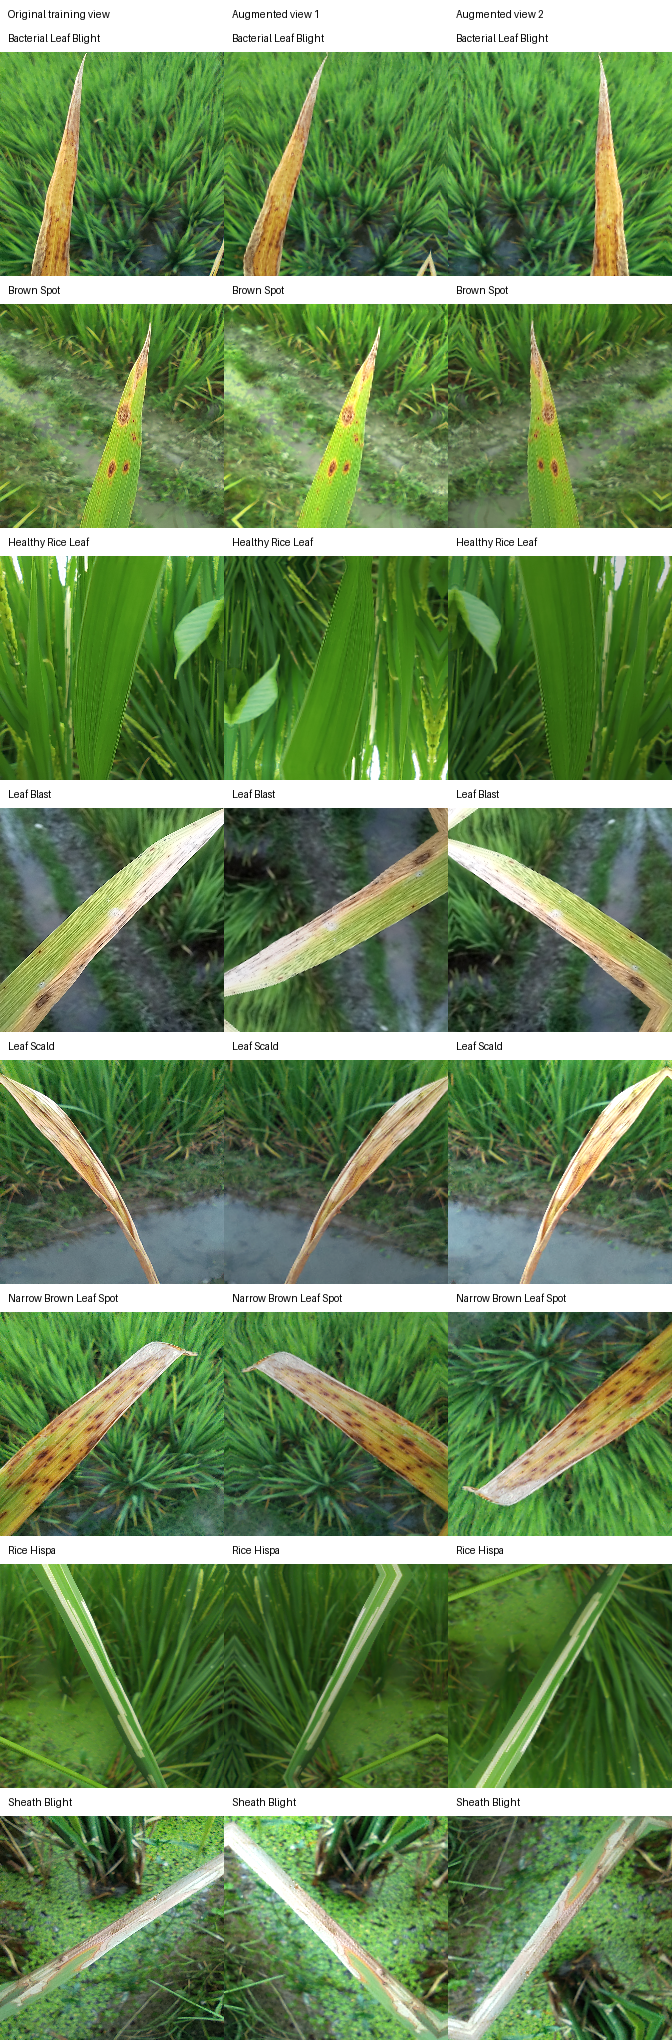

In [4]:
from IPython.display import Image as DisplayImage, display

display(DisplayImage(filename="/kaggle/working/paper9_twin_cnn_d1/preprocessing/Paper9_D1_Augmentation_Preview.png"))

In [5]:
import csv
import json
import shutil
import tempfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter

import keras
import numpy as np
import tensorflow as tf


PAPER9_D1_FEATURE_ROOT = Path("/kaggle/working/paper9_twin_cnn_d1/features")
PAPER9_FEATURE_BATCH_SIZE = 32
PAPER9_FEATURE_READERS = 4


def write_paper9_feature_index(path, entries):
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream, lineterminator="\n")
        writer.writerow(("feature_row", "split", "rel_path", "class_id", "view_id"))
        for index, (row, view_id) in enumerate(entries):
            writer.writerow((index, row["split"], row["rel_path"], row["class_id"], view_id))


def read_paper9_feature_image(entry):
    row, view_id = entry
    return paper9_load_rgb_view(paper9_d1_image_root, row, view_id)


def extract_paper9_donor_features(name, width, entries, weight_info, run_dir):
    weight_path = Path(weight_info["file"])
    if paper9_weight_digest(weight_path, "sha256") != weight_info["sha256"]:
        raise ValueError(f"ImageNet weight SHA-256 mismatch: {name}")

    shape = (len(entries), width)
    final_path = run_dir / f"{name}_features.npy"
    partial_path = run_dir / f"{name}_features.partial.npy"
    keras.backend.clear_session()
    started = perf_counter()
    data = np.lib.format.open_memmap(partial_path, mode="w+", dtype=np.float32, shape=shape)
    try:
        with tf.device("/GPU:0"), ThreadPoolExecutor(max_workers=PAPER9_FEATURE_READERS) as readers:
            donor = build_paper9_donor(name, weights=str(weight_path))
            if donor.trainable_weights or int(donor.output_shape[-1]) != width:
                raise ValueError(f"Unexpected extractor configuration: {name}")
            batch_count = (len(entries) + PAPER9_FEATURE_BATCH_SIZE - 1) // PAPER9_FEATURE_BATCH_SIZE
            for batch_number, start in enumerate(range(0, len(entries), PAPER9_FEATURE_BATCH_SIZE), 1):
                end = min(start + PAPER9_FEATURE_BATCH_SIZE, len(entries))
                images = np.stack(list(readers.map(read_paper9_feature_image, entries[start:end])))
                if images.dtype != np.float32 or images.shape != (end - start, *PAPER9_IMAGE_SHAPE):
                    raise ValueError(f"Unexpected image batch for {name}: {images.shape}, {images.dtype}")
                if not np.isfinite(images).all() or images.min() < 0 or images.max() > 1:
                    raise ValueError(f"Invalid normalized images for {name} at row {start}")
                features = donor(images, training=False).numpy()
                if features.shape != (end - start, width) or features.dtype != np.float32:
                    raise ValueError(f"Unexpected features for {name}: {features.shape}, {features.dtype}")
                if not np.isfinite(features).all():
                    raise ValueError(f"Nonfinite features for {name} at row {start}")
                data[start:end] = features
                if batch_number == 1 or batch_number % 50 == 0 or batch_number == batch_count:
                    print(f"{name}: batch {batch_number}/{batch_count} | {end:,}/{len(entries):,} views", flush=True)
            del donor
        data.flush()
    finally:
        del data
        keras.backend.clear_session()

    partial_path.replace(final_path)
    reopened = np.load(final_path, mmap_mode="r", allow_pickle=False)
    if reopened.shape != shape or reopened.dtype != np.float32:
        raise ValueError(f"Feature cache failed reload: {final_path}")
    del reopened
    elapsed = perf_counter() - started
    digest = paper9_weight_digest(final_path, "sha256")
    print(f"{name}: saved {shape} | {elapsed:.1f} s | SHA-256 {digest}", flush=True)
    return {
        "file": final_path.name,
        "shape": list(shape),
        "dtype": "float32",
        "sha256": digest,
        "imagenet_sha256": weight_info["sha256"],
        "feature_tap": weight_info["feature_tap"],
        "seconds": round(elapsed, 3),
    }


def extract_paper9_d1_features():
    if not tf.config.list_physical_devices("GPU"):
        raise RuntimeError("Enable a GPU in the Kaggle notebook before running Step 4.")
    keras.mixed_precision.set_global_policy("float32")
    entries = paper9_d1_feature_entries
    counts = Counter(row["split"] for row, _ in entries)
    view_counts = Counter((row["split"], view_id) for row, view_id in entries)
    expected = {("train", 0): 1156, ("train", 1): 1156, ("train", 2): 1156, ("val", 0): 247}
    if view_counts != expected or len({(row["rel_path"], view_id) for row, view_id in entries}) != len(entries):
        raise ValueError(f"Unexpected feature view plan: {view_counts}")

    PAPER9_D1_FEATURE_ROOT.mkdir(parents=True, exist_ok=True)
    required_bytes = len(entries) * sum(PAPER9_DONOR_WIDTHS.values()) * np.dtype(np.float32).itemsize
    if shutil.disk_usage(PAPER9_D1_FEATURE_ROOT).free < required_bytes + 16 * 2**20:
        raise RuntimeError("Insufficient Kaggle working space for the feature files.")
    run_dir = Path(tempfile.mkdtemp(prefix="d1_", dir=PAPER9_D1_FEATURE_ROOT))
    index_path = run_dir / "Paper9_D1_Feature_Index.csv"
    write_paper9_feature_index(index_path, entries)
    print(f"D1 feature directory: {run_dir}", flush=True)
    print(f"Train views: {counts['train']:,} | validation views: {counts['val']:,} | /GPU:0", flush=True)

    report = {
        "manifest_sha256": PAPER9_D1_MANIFEST_SHA256,
        "preprocessing_report_sha256": paper9_weight_digest(paper9_d1_preprocessing_report, "sha256"),
        "counts": dict(counts),
        "index_file": index_path.name,
        "index_sha256": paper9_weight_digest(index_path, "sha256"),
        "donor_order": list(PAPER9_DONOR_WIDTHS),
        "fused_width": sum(PAPER9_DONOR_WIDTHS.values()),
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
        "batch_size": PAPER9_FEATURE_BATCH_SIZE,
        "donors": {},
    }
    for name, width in PAPER9_DONOR_WIDTHS.items():
        report["donors"][name] = extract_paper9_donor_features(
            name, width, entries, paper9_d1_imagenet_donors[name], run_dir
        )

    report_path = run_dir / "Paper9_D1_Feature_Extraction.json"
    temporary_report = report_path.with_suffix(".json.tmp")
    temporary_report.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    temporary_report.replace(report_path)
    print(f"Shared feature index: {index_path}")
    print(f"Feature extraction report: {report_path}")
    print("PAPER 9 D1 FEATURE EXTRACTION PASSED")
    return run_dir, report_path


paper9_d1_feature_dir, paper9_d1_feature_report = extract_paper9_d1_features()


D1 feature directory: /kaggle/working/paper9_twin_cnn_d1/features/d1_tr4m8mab
Train views: 3,468 | validation views: 247 | /GPU:0
vgg16: batch 1/117 | 32/3,715 views
vgg16: batch 50/117 | 1,600/3,715 views
vgg16: batch 100/117 | 3,200/3,715 views
vgg16: batch 117/117 | 3,715/3,715 views
vgg16: saved (3715, 4096) | 81.9 s | SHA-256 df324ec018392785e3abece593a1ce6a42bb206a15b4682d5222cef4130b215a
resnet50: batch 1/117 | 32/3,715 views
resnet50: batch 50/117 | 1,600/3,715 views
resnet50: batch 100/117 | 3,200/3,715 views
resnet50: batch 117/117 | 3,715/3,715 views
resnet50: saved (3715, 2048) | 88.4 s | SHA-256 fc3c3f3fa0fca6fb586b678761d9ab9b05d0c4f9c9323a360a4c4484708bf40e
inception_v3: batch 1/117 | 32/3,715 views
inception_v3: batch 50/117 | 1,600/3,715 views
inception_v3: batch 100/117 | 3,200/3,715 views
inception_v3: batch 117/117 | 3,715/3,715 views
inception_v3: saved (3715, 2048) | 98.6 s | SHA-256 c1aa0bb3eaf212d089c84c33f105eb6c0ac99148de28a20420dfdd0b24a3c2a9
Shared feature i

In [6]:
import csv
import json
import os
import tempfile
from pathlib import Path
from time import perf_counter

import numpy as np
import sklearn
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits


PAPER9_PCA_VARIANCE_TARGET = 0.95


def load_paper9_d1_fused_features():
    report = json.loads(paper9_d1_feature_report.read_text(encoding="utf-8"))
    if report["manifest_sha256"] != PAPER9_D1_MANIFEST_SHA256:
        raise ValueError("Feature report uses a different D1 manifest.")
    if report["donor_order"] != list(PAPER9_DONOR_WIDTHS) or report["fused_width"] != 8192:
        raise ValueError("Unexpected feature order or fused width.")
    if report["counts"] != {"train": 3468, "val": 247}:
        raise ValueError(f"Unexpected feature counts: {report['counts']}")
    index_path = paper9_d1_feature_dir / report["index_file"]
    if paper9_weight_digest(index_path, "sha256") != report["index_sha256"]:
        raise ValueError("Feature index SHA-256 mismatch.")

    with index_path.open(newline="", encoding="utf-8") as stream:
        index_rows = list(csv.DictReader(stream))
    for row_number, (indexed, (row, view_id)) in enumerate(zip(index_rows, paper9_d1_feature_entries, strict=True)):
        actual = (int(indexed["feature_row"]), indexed["split"], indexed["rel_path"],
                  int(indexed["class_id"]), int(indexed["view_id"]))
        expected = (row_number, row["split"], row["rel_path"], int(row["class_id"]), view_id)
        if actual != expected:
            raise ValueError(f"Feature index differs from the verified view plan at row {row_number}.")

    n_train, n_val = report["counts"]["train"], report["counts"]["val"]
    if [row["split"] for row in index_rows] != ["train"] * n_train + ["val"] * n_val:
        raise ValueError("Feature rows are not in the expected training and validation blocks.")
    labels = np.array([int(row["class_id"]) for row in index_rows], dtype=np.int64)
    fused = np.empty((n_train + n_val, 8192), dtype=np.float32)
    start = 0
    for name, width in PAPER9_DONOR_WIDTHS.items():
        info = report["donors"][name]
        feature_path = paper9_d1_feature_dir / info["file"]
        if paper9_weight_digest(feature_path, "sha256") != info["sha256"]:
            raise ValueError(f"Feature array SHA-256 mismatch: {name}")
        if info["imagenet_sha256"] != paper9_d1_imagenet_donors[name]["sha256"]:
            raise ValueError(f"ImageNet provenance mismatch: {name}")
        values = np.load(feature_path, mmap_mode="r", allow_pickle=False)
        if values.shape != (len(index_rows), width) or values.dtype != np.float32:
            raise ValueError(f"Unexpected array for {name}: {values.shape}, {values.dtype}")
        end = start + width
        fused[:, start:end] = values
        print(f"{name}: verified {values.shape} | fused columns {start} through {end - 1}", flush=True)
        start = end
        del values
    return fused, labels, n_train, index_path


def fit_paper9_training_pca(train_features, val_features):
    pca = PCA(n_components=PAPER9_PCA_VARIANCE_TARGET, svd_solver="full", whiten=False)
    threads = min(4, len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count() or 1)
    with threadpool_limits(limits=threads, user_api="blas"):
        pca.fit(train_features)
        train_scores = np.ascontiguousarray(pca.transform(train_features), dtype=np.float32)
        val_scores = np.ascontiguousarray(pca.transform(val_features), dtype=np.float32)
    return pca, train_scores, val_scores, threads


def fit_paper9_d1_pca():
    fused, labels, n_train, index_path = load_paper9_d1_fused_features()
    print(f"Fused feature matrix: {fused.shape} | float32", flush=True)
    print(f"Fitting centered PCA on {n_train:,} training views | target variance 95%", flush=True)
    started = perf_counter()
    pca, train_scores, val_scores, threads = fit_paper9_training_pca(fused[:n_train], fused[n_train:])
    elapsed = perf_counter() - started
    components = int(pca.n_components_)
    variance = float(np.sum(pca.explained_variance_ratio_, dtype=np.float64))
    if components < 4 or not PAPER9_PCA_VARIANCE_TARGET - 1e-6 <= variance <= 1.000001:
        raise ValueError(f"Unexpected PCA result: {components} components, variance {variance}")
    if not np.isfinite(train_scores).all() or not np.isfinite(val_scores).all():
        raise ValueError("PCA projection contains nonfinite values.")
    np.testing.assert_allclose(pca.mean_, fused[:n_train].mean(axis=0), atol=1e-6)
    np.testing.assert_allclose(
        val_scores[:4],
        (fused[n_train:n_train + 4] - pca.mean_) @ pca.components_.T,
        rtol=1e-4,
        atol=2e-3,
    )
    del fused

    output_dir = Path(tempfile.mkdtemp(prefix="pca_", dir=paper9_d1_feature_dir))
    files = {
        "projection": output_dir / "Paper9_D1_PCA_Projection.npz",
        "train": output_dir / "Paper9_D1_PCA_Train.npy",
        "val": output_dir / "Paper9_D1_PCA_Validation.npy",
        "train_labels": output_dir / "Paper9_D1_Train_Labels.npy",
        "val_labels": output_dir / "Paper9_D1_Validation_Labels.npy",
    }
    np.savez(
        files["projection"],
        mean=pca.mean_,
        components=pca.components_,
        explained_variance_ratio=pca.explained_variance_ratio_,
    )
    for name, data in {
        "train": train_scores, "val": val_scores,
        "train_labels": labels[:n_train], "val_labels": labels[n_train:],
    }.items():
        np.save(files[name], data, allow_pickle=False)

    report = {
        "manifest_sha256": PAPER9_D1_MANIFEST_SHA256,
        "feature_report_sha256": paper9_weight_digest(paper9_d1_feature_report, "sha256"),
        "feature_index_sha256": paper9_weight_digest(index_path, "sha256"),
        "donor_order": list(PAPER9_DONOR_WIDTHS),
        "input_width": 8192,
        "fit_split": "train",
        "fit_views": n_train,
        "validation_views": len(val_scores),
        "target_explained_variance": PAPER9_PCA_VARIANCE_TARGET,
        "retained_explained_variance": variance,
        "component_count": components,
        "centered": True,
        "whiten": False,
        "solver": "full",
        "blas_thread_limit": threads,
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
        "fit_and_transform_seconds": round(elapsed, 3),
        "files": {
            name: {"file": path.name, "sha256": paper9_weight_digest(path, "sha256")}
            for name, path in files.items()
        },
    }
    report_path = output_dir / "Paper9_D1_PCA_Report.json"
    temporary_report = report_path.with_suffix(".json.tmp")
    temporary_report.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    temporary_report.replace(report_path)
    print(f"PCA components: {components:,} | retained training variance: {variance:.4%} | {elapsed:.1f} s")
    print(f"Projected training: {train_scores.shape} | validation: {val_scores.shape}")
    print(f"PCA report: {report_path}")
    print("PAPER 9 D1 FUSION AND PCA PASSED")
    return output_dir, report_path


paper9_d1_pca_dir, paper9_d1_pca_report = fit_paper9_d1_pca()


vgg16: verified (3715, 4096) | fused columns 0 through 4095
resnet50: verified (3715, 2048) | fused columns 4096 through 6143
inception_v3: verified (3715, 2048) | fused columns 6144 through 8191
Fused feature matrix: (3715, 8192) | float32
Fitting centered PCA on 3,468 training views | target variance 95%
PCA components: 534 | retained training variance: 95.0091% | 13.9 s
Projected training: (3468, 534) | validation: (247, 534)
PCA report: /kaggle/working/paper9_twin_cnn_d1/features/d1_tr4m8mab/pca_y1u380e_/Paper9_D1_PCA_Report.json
PAPER 9 D1 FUSION AND PCA PASSED


In [7]:
import json
import tempfile
from pathlib import Path
from time import perf_counter

import keras
import numpy as np


def load_paper9_pca_arrays():
    report = json.loads(paper9_d1_pca_report.read_text(encoding="utf-8"))
    assert report["manifest_sha256"] == PAPER9_D1_MANIFEST_SHA256
    assert report["fit_split"] == "train" and report["fit_views"] == 3468
    arrays = {}
    for name in ("train", "val", "train_labels", "val_labels"):
        info = report["files"][name]
        path = paper9_d1_pca_dir / info["file"]
        assert paper9_weight_digest(path, "sha256") == info["sha256"], name
        arrays[name] = np.load(path, allow_pickle=False)
    width = report["component_count"]
    for split, count in (("train", 3468), ("val", 247)):
        data, labels = arrays[split], arrays[f"{split}_labels"]
        assert data.shape == (count, width) and data.dtype == np.float32
        assert np.isfinite(data).all() and labels.shape == (count,)
        assert np.array_equal(np.unique(labels), np.arange(len(PAPER9_D1_CLASS_NAMES)))
    return arrays, width


def train_paper9_d1():
    arrays, width = load_paper9_pca_arrays()
    root = Path("/kaggle/working/paper9_twin_cnn_d1/training")
    root.mkdir(parents=True, exist_ok=True)
    run_dir = Path(tempfile.mkdtemp(prefix="run_", dir=root))
    checkpoint = run_dir / "Paper9_D1_Best_Validation.weights.h5"
    keras.backend.clear_session()
    keras.utils.set_random_seed(PAPER9_SEED)
    class_count = len(PAPER9_D1_CLASS_NAMES)
    model = build_paper9_classifier(width, class_count)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999),
        loss=keras.losses.CategoricalCrossentropy(),
        metrics=[keras.metrics.CategoricalAccuracy(name="accuracy")],
        jit_compile=False,
    )
    train_y = keras.utils.to_categorical(arrays["train_labels"], class_count)
    val_y = keras.utils.to_categorical(arrays["val_labels"], class_count)
    sample = model(arrays["train"][:32], training=False).numpy()
    np.testing.assert_allclose(sample.sum(axis=1), 1, atol=1e-6)
    print(f"Paper 9 D1 | {width} PCA components | {model.count_params():,} classifier parameters", flush=True)
    print(f"Training directory: {run_dir}", flush=True)
    started = perf_counter()
    history = model.fit(
        arrays["train"], train_y,
        validation_data=(arrays["val"], val_y),
        batch_size=32,
        epochs=50,
        shuffle=True,
        verbose=2,
        callbacks=[
            keras.callbacks.TerminateOnNaN(),
            keras.callbacks.CSVLogger(str(run_dir / "Paper9_D1_Training_History.csv")),
            keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", mode="min",
                                            save_best_only=True, save_weights_only=True),
        ],
    ).history
    assert len(history["val_loss"]) == 50 and all(np.isfinite(values).all() for values in history.values())
    best = int(np.argmin(history["val_loss"]))
    model.load_weights(str(checkpoint))
    validation = model.evaluate(arrays["val"], val_y, batch_size=32, verbose=0, return_dict=True)
    np.testing.assert_allclose(validation["loss"], history["val_loss"][best], rtol=1e-4, atol=1e-6)
    np.testing.assert_allclose(validation["accuracy"], history["val_accuracy"][best], atol=1e-6)
    digest = paper9_weight_digest(checkpoint, "sha256")
    summary = {
        "manifest_sha256": PAPER9_D1_MANIFEST_SHA256,
        "pca_report_sha256": paper9_weight_digest(paper9_d1_pca_report, "sha256"),
        "component_count": width,
        "seed": PAPER9_SEED,
        "epochs": 50,
        "batch_size": 32,
        "optimizer": model.optimizer.get_config(),
        "loss": "categorical_crossentropy",
        "checkpoint_selection": "minimum validation loss",
        "best_epoch": best + 1,
        "validation": validation,
        "checkpoint": checkpoint.name,
        "checkpoint_sha256": digest,
        "training_seconds": round(perf_counter() - started, 3),
        "history": history,
    }
    summary_path = run_dir / "Paper9_D1_Training_Summary.json"
    summary_path.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
    print(f"Best epoch: {best + 1} | validation loss: {validation['loss']:.6f} | accuracy: {validation['accuracy']:.4%}")
    print(f"Checkpoint SHA-256: {digest}")
    print(f"Training summary: {summary_path}")
    print("PAPER 9 D1 TRAINING PASSED")
    return run_dir, summary_path


paper9_d1_training_dir, paper9_d1_training_summary = train_paper9_d1()


Paper 9 D1 | 534 PCA components | 2,181,512 classifier parameters
Training directory: /kaggle/working/paper9_twin_cnn_d1/training/run_ip_pmvx0
Epoch 1/50
109/109 - 3s - 32ms/step - accuracy: 0.4164 - loss: 1.7540 - val_accuracy: 0.5992 - val_loss: 1.2767
Epoch 2/50
109/109 - 1s - 8ms/step - accuracy: 0.6889 - loss: 0.9362 - val_accuracy: 0.6437 - val_loss: 1.1331
Epoch 3/50
109/109 - 1s - 7ms/step - accuracy: 0.7892 - loss: 0.6353 - val_accuracy: 0.6073 - val_loss: 1.2244
Epoch 4/50
109/109 - 1s - 7ms/step - accuracy: 0.8264 - loss: 0.4974 - val_accuracy: 0.6032 - val_loss: 1.1983
Epoch 5/50
109/109 - 1s - 7ms/step - accuracy: 0.8682 - loss: 0.3871 - val_accuracy: 0.6194 - val_loss: 1.2341
Epoch 6/50
109/109 - 1s - 8ms/step - accuracy: 0.8841 - loss: 0.3407 - val_accuracy: 0.6802 - val_loss: 1.0778
Epoch 7/50
109/109 - 1s - 7ms/step - accuracy: 0.9270 - loss: 0.2365 - val_accuracy: 0.6640 - val_loss: 1.2887
Epoch 8/50
109/109 - 1s - 7ms/step - accuracy: 0.9432 - loss: 0.1745 - val_accu

In [8]:
import csv
import json
import tempfile
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, log_loss, roc_auc_score, roc_curve


def evaluate_paper9_d1():
    pca = json.loads(paper9_d1_pca_report.read_text(encoding="utf-8"))
    training = json.loads(paper9_d1_training_summary.read_text(encoding="utf-8"))
    assert pca["manifest_sha256"] == training["manifest_sha256"] == PAPER9_D1_MANIFEST_SHA256
    assert training["pca_report_sha256"] == paper9_weight_digest(paper9_d1_pca_report, "sha256")
    assert paper9_weight_digest(paper9_d1_manifest_path, "sha256") == PAPER9_D1_MANIFEST_SHA256
    checkpoint = paper9_d1_training_dir / training["checkpoint"]
    assert paper9_weight_digest(checkpoint, "sha256") == training["checkpoint_sha256"]
    projection = paper9_d1_pca_dir / pca["files"]["projection"]["file"]
    assert paper9_weight_digest(projection, "sha256") == pca["files"]["projection"]["sha256"]
    with np.load(projection, allow_pickle=False) as archive:
        mean, components = archive["mean"], archive["components"]
    width = training["component_count"]
    assert mean.shape == (8192,) and components.shape == (width, 8192)
    rows = sorted((row for row in paper9_d1_rows if row["split"] == "test"), key=lambda row: row["rel_path"])
    labels = np.array([int(row["class_id"]) for row in rows])
    names = PAPER9_D1_CLASS_NAMES
    ids = np.arange(len(names))
    assert len(rows) == 248 and np.array_equal(np.unique(labels), ids)
    print(f"Locked epoch {training['best_epoch']} checkpoint | SHA-256 {training['checkpoint_sha256']}", flush=True)

    feature_blocks = []
    for name, size in PAPER9_DONOR_WIDTHS.items():
        keras.backend.clear_session()
        info = paper9_d1_imagenet_donors[name]
        weights = Path(info["file"])
        assert paper9_weight_digest(weights, "sha256") == info["sha256"]
        with tf.device("/GPU:0"):
            donor = build_paper9_donor(name, weights=str(weights))
            block = np.empty((len(rows), size), dtype=np.float32)
            for start in range(0, len(rows), 32):
                end = min(start + 32, len(rows))
                images = np.stack([paper9_load_rgb_view(paper9_d1_image_root, row, 0) for row in rows[start:end]])
                block[start:end] = donor(images, training=False).numpy()
            del donor
        assert np.isfinite(block).all()
        feature_blocks.append(block)
        print(f"Test features from {name}: {block.shape}", flush=True)
    keras.backend.clear_session()
    projected = (np.concatenate(feature_blocks, axis=1) - mean) @ components.T
    model = build_paper9_classifier(width, len(names))
    model.load_weights(str(checkpoint))
    probabilities = np.concatenate([
        model(projected[start:start + 32], training=False).numpy()
        for start in range(0, len(rows), 32)
    ]).astype(np.float64)
    assert probabilities.shape == (len(rows), len(names)) and np.isfinite(probabilities).all()
    sums = probabilities.sum(axis=1, keepdims=True)
    np.testing.assert_allclose(sums, 1, atol=1e-6)
    probabilities /= sums
    predicted = probabilities.argmax(axis=1)
    matrix = confusion_matrix(labels, predicted, labels=ids)
    correct = int(np.trace(matrix))
    report = classification_report(labels, predicted, labels=ids, target_names=names,
                                   output_dict=True, zero_division=0)
    metrics = {
        "accuracy": correct / len(rows),
        "correct": correct,
        "n_test": len(rows),
        "macro_precision": report["macro avg"]["precision"],
        "macro_recall": report["macro avg"]["recall"],
        "macro_f1": report["macro avg"]["f1-score"],
        "macro_ovr_auc": roc_auc_score(labels, probabilities, labels=ids, multi_class="ovr", average="macro"),
        "weighted_ovr_auc": roc_auc_score(labels, probabilities, labels=ids, multi_class="ovr", average="weighted"),
        "test_loss": log_loss(labels, probabilities, labels=ids),
    }
    out = Path(tempfile.mkdtemp(prefix="test_", dir=paper9_d1_training_dir))
    metrics_path = out / "Paper9_D1_Test_Metrics.json"
    metrics_path.write_text(json.dumps({
        "manifest_sha256": PAPER9_D1_MANIFEST_SHA256,
        "checkpoint_sha256": training["checkpoint_sha256"],
        "best_epoch": training["best_epoch"],
        "pca_projection_sha256": pca["files"]["projection"]["sha256"],
        "class_names": names,
        "metrics": metrics,
        "classification_report": report,
        "confusion_matrix": matrix.tolist(),
    }, indent=2) + "\n", encoding="utf-8")
    predictions_path = out / "Paper9_D1_Test_Predictions.csv"
    with predictions_path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow(["rel_path", "true_class", "predicted_class", *[f"p_{name}" for name in names]])
        for row, true, pred, scores in zip(rows, labels, predicted, probabilities, strict=True):
            writer.writerow([row["rel_path"], names[true], names[pred], *scores])

    fig, ax = plt.subplots(figsize=(10, 7))
    colors = ax.imshow(matrix, cmap="Blues")
    fig.colorbar(colors, ax=ax)
    ax.set(xticks=ids, yticks=ids, xticklabels=names, yticklabels=names,
           xlabel="Predicted class", ylabel="True class", title="Paper 9 D1 test confusion matrix")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
    for i in ids:
        for j in ids:
            ax.text(j, i, matrix[i, j], ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")
    fig.tight_layout()
    fig.savefig(out / "Paper9_D1_Confusion_Matrix.png", dpi=160)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 5))
    for i, name in enumerate(names):
        truth = labels == i
        fpr, tpr, _ = roc_curve(truth, probabilities[:, i])
        ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(truth, probabilities[:, i]):.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Paper 9 D1 one-vs-rest ROC")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "Paper9_D1_ROC.png", dpi=160)
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    history = training["history"]
    epochs = range(1, len(history["loss"]) + 1)
    for ax, metric in zip(axes, ("loss", "accuracy"), strict=True):
        ax.plot(epochs, history[metric], label="Train")
        ax.plot(epochs, history[f"val_{metric}"], label="Validation")
        ax.axvline(training["best_epoch"], color="gray", linestyle="--", label="Selected epoch")
        ax.set(xlabel="Epoch", ylabel=metric.capitalize())
        ax.legend()
    fig.tight_layout()
    fig.savefig(out / "Paper9_D1_Training_Curves.png", dpi=160)
    plt.close(fig)

    sources = [
        *sorted(out.iterdir()), checkpoint, projection, paper9_d1_pca_report,
        paper9_d1_training_summary, paper9_d1_training_dir / "Paper9_D1_Training_History.csv",
        paper9_d1_feature_report, paper9_d1_feature_dir / "Paper9_D1_Feature_Index.csv",
        paper9_d1_imagenet_report, paper9_d1_preprocessing_report,
        paper9_d1_preprocessing_report.parent / "Paper9_D1_Augmentation_Preview.png",
    ]
    bundle = out / "Paper9_D1_Experiment_Evidence.zip"
    with ZipFile(bundle, "w", compression=ZIP_DEFLATED, compresslevel=3) as archive:
        for source in sources:
            archive.write(source, source.name)
    with ZipFile(bundle) as archive:
        assert archive.testzip() is None and len(archive.namelist()) == len(sources)
    print(f"Test accuracy: {metrics['accuracy']:.4%} ({correct}/{len(rows)})")
    for name in ("macro_precision", "macro_recall", "macro_f1", "macro_ovr_auc", "weighted_ovr_auc", "test_loss"):
        print(f"{name}: {metrics[name]:.6f}")
    print(f"Evidence bundle: {bundle}")
    print(f"Evidence SHA-256: {paper9_weight_digest(bundle, 'sha256')}")
    print("PAPER 9 D1 EVALUATION AND BACKUP PASSED")
    return out, bundle


paper9_d1_test_dir, paper9_d1_evidence = evaluate_paper9_d1()


Locked epoch 6 checkpoint | SHA-256 d0e37e87b2b386d35169b26bbf6e1cf1c7cc95ffa61018e1ba7ec6f4369f964e
Test features from vgg16: (248, 4096)
Test features from resnet50: (248, 2048)
Test features from inception_v3: (248, 2048)
Test accuracy: 63.3065% (157/248)
macro_precision: 0.674356
macro_recall: 0.619569
macro_f1: 0.614698
macro_ovr_auc: 0.910136
weighted_ovr_auc: 0.912601
test_loss: 1.200678
Evidence bundle: /kaggle/working/paper9_twin_cnn_d1/training/run_ip_pmvx0/test_de03_45j/Paper9_D1_Experiment_Evidence.zip
Evidence SHA-256: 81ee6ae7b21c1c59cc4b9fa0f74518d60e1739efb9741015f538036c2bd3eb98
PAPER 9 D1 EVALUATION AND BACKUP PASSED
